import pandas as pd
import plotly.express as px


In [28]:
import pprint

import pandas as pd
import plotly.express as px
from pathlib import Path
import pprint as pp

In [7]:
# Dictionary für die DataFrames
dataframes = {}

data_folder = Path("data")

# Alle CSV-Dateien im Ordner durchlaufen
for file in data_folder.glob("*.csv"):
    df = pd.read_csv(file)
    dataframes[file.stem] = df

In [30]:


for i in dataframes:
    print(i)
    types = dataframes[i].dtypes
    print(types)
    print("")

categories
product_category_name            str
product_category_name_english    str
dtype: object

customers
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

geolocation
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

items
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

orders
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_

In [37]:
for i in dataframes:
    print(i)
    print(dataframes[i].isna().sum())
    print("")

categories
product_category_name            0
product_category_name_english    2
dtype: int64

customers
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

geolocation
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

items
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

payments
order_id   

categories
customers
geolocation
items
orders
payments
pilot_support
products
reviews
sellers
service_experiment
service_observation


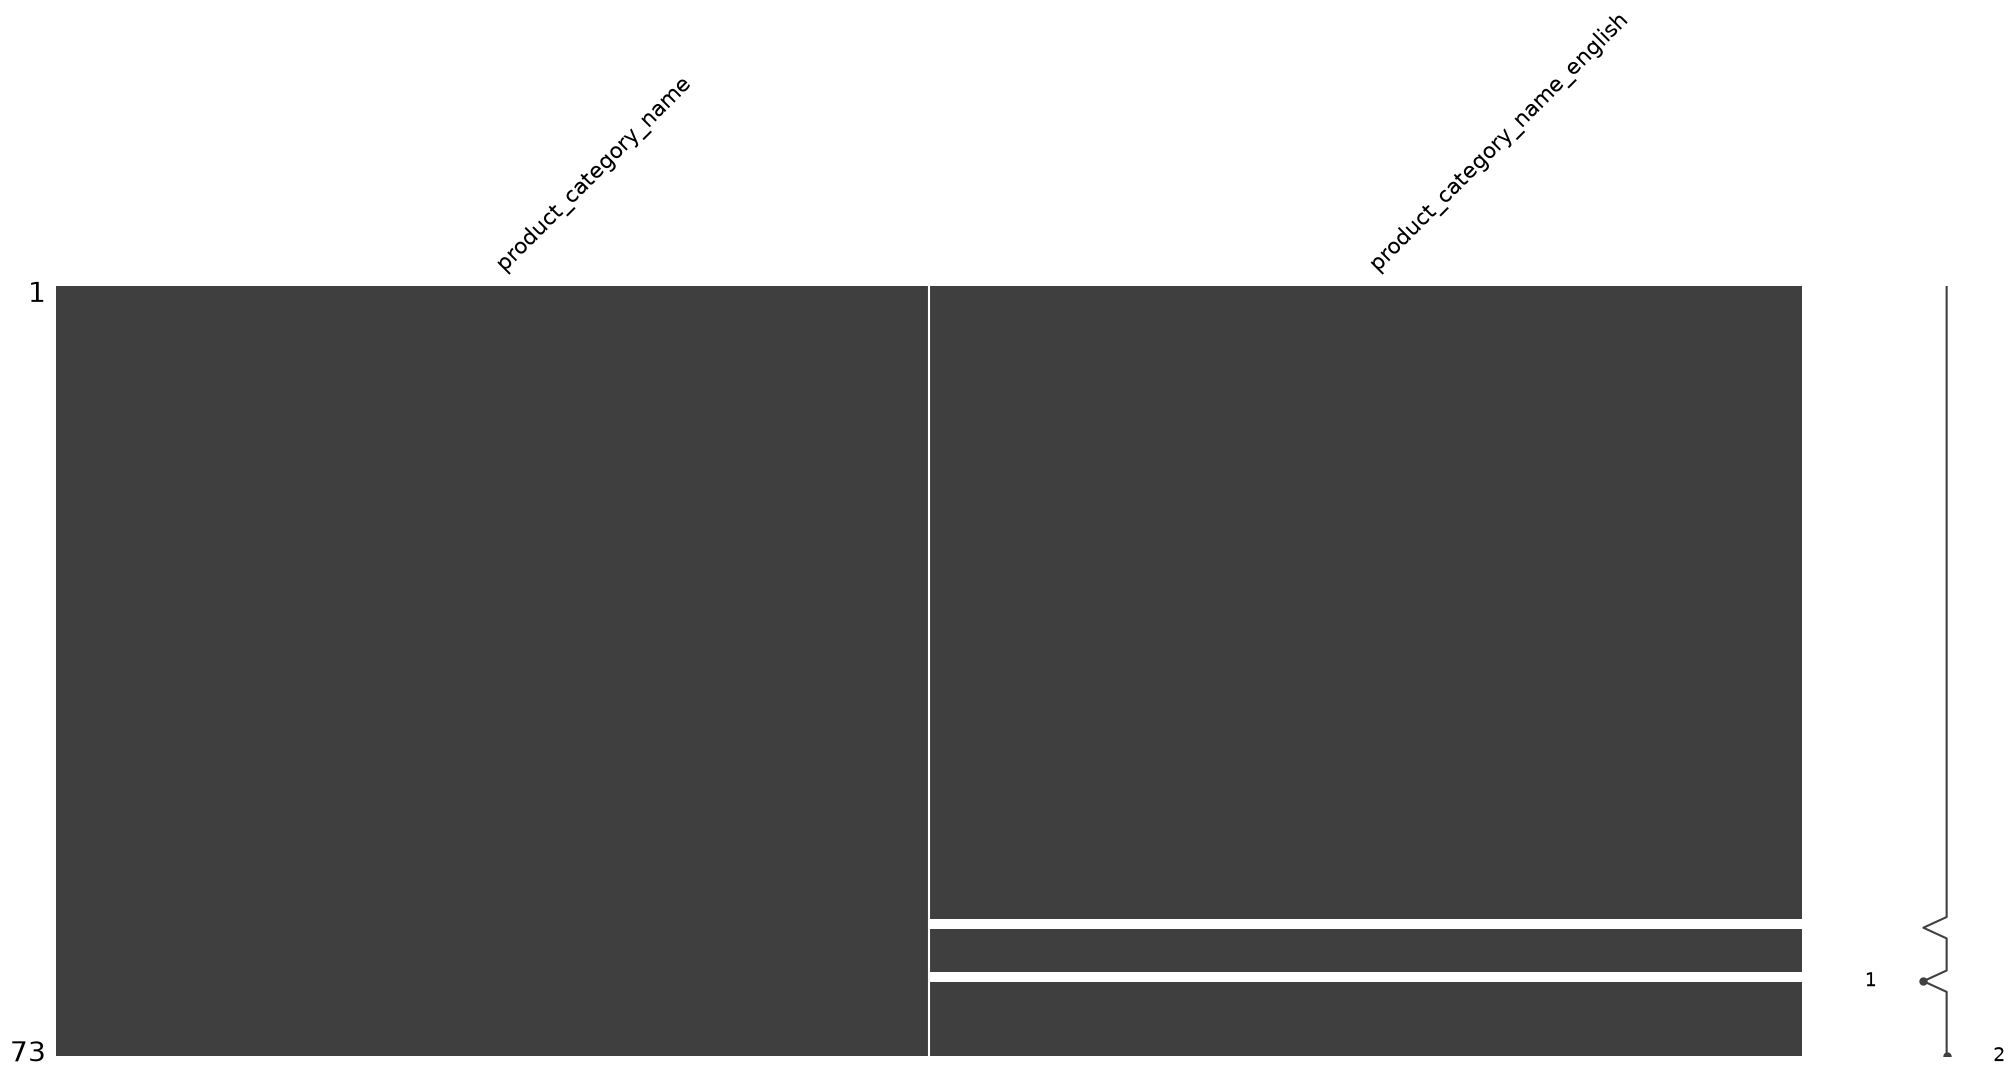

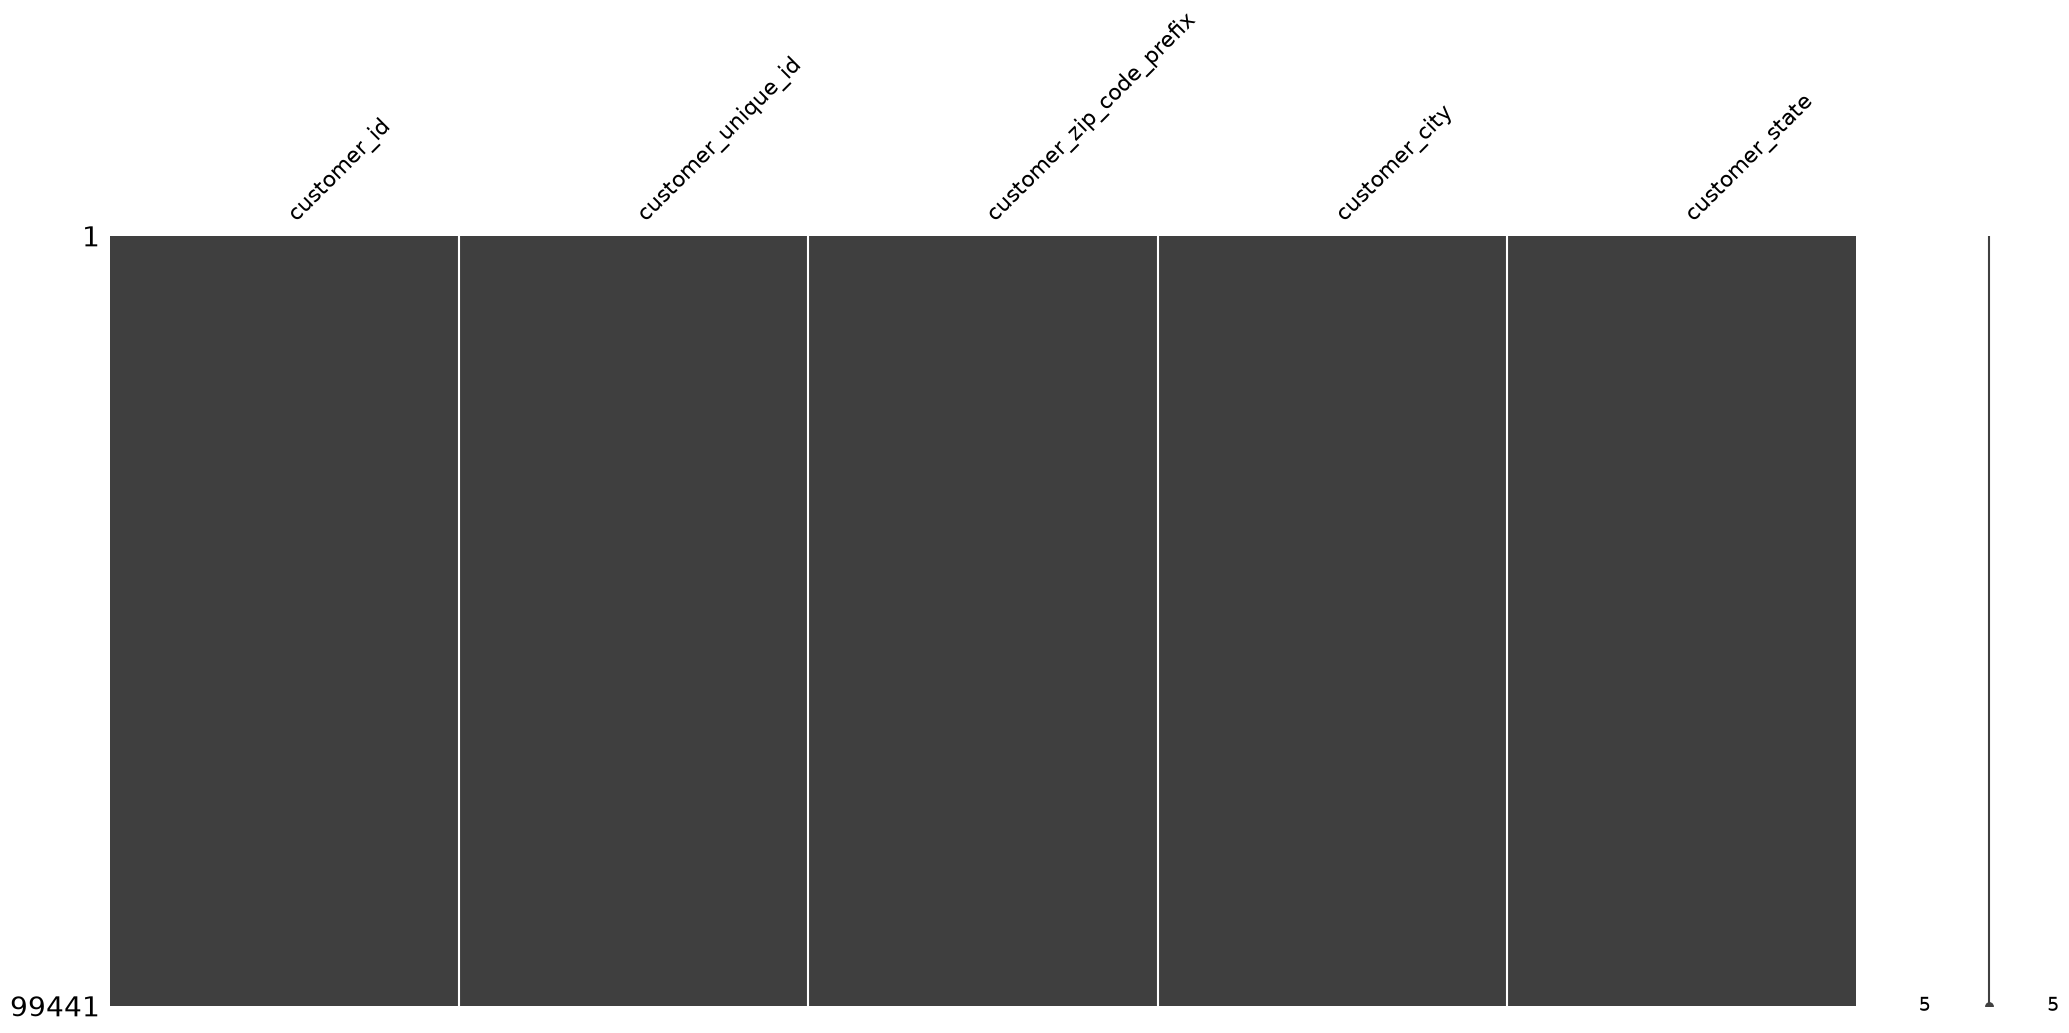

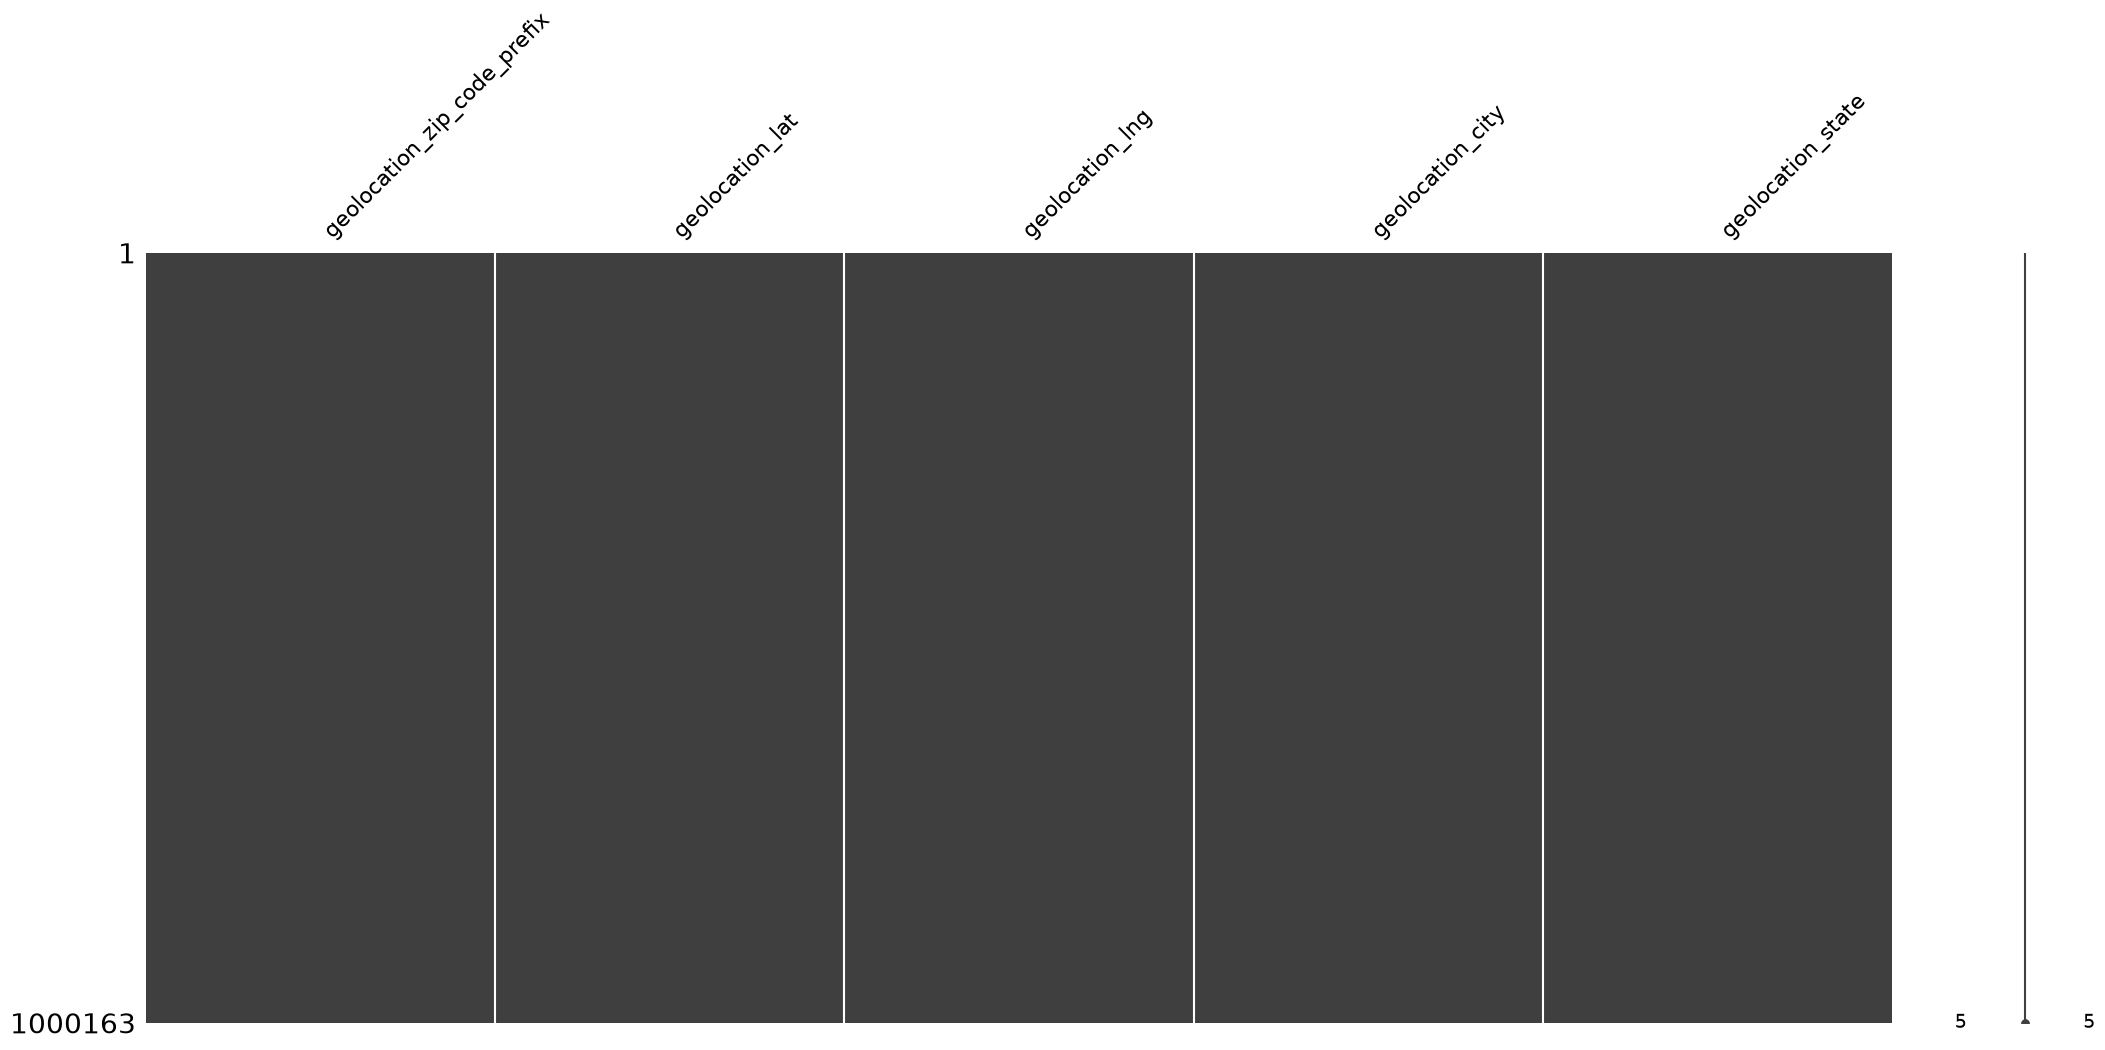

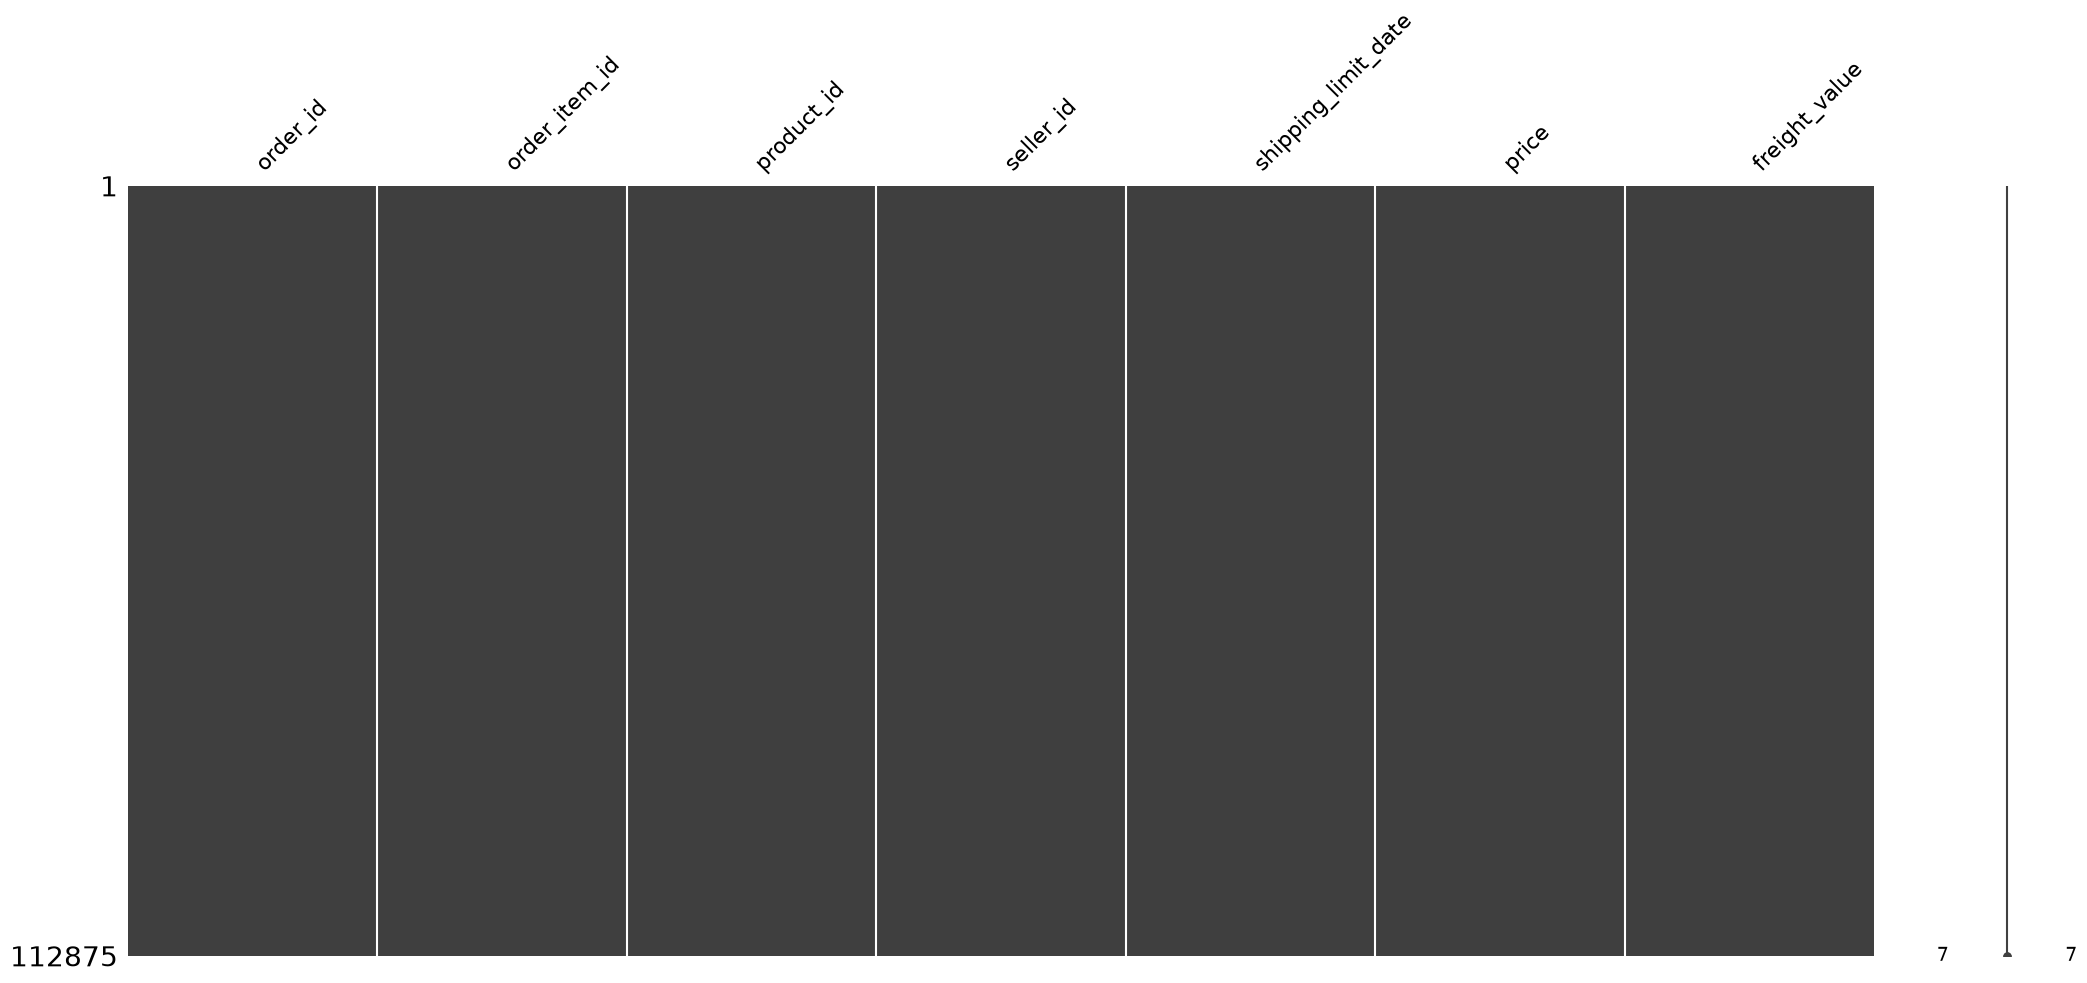

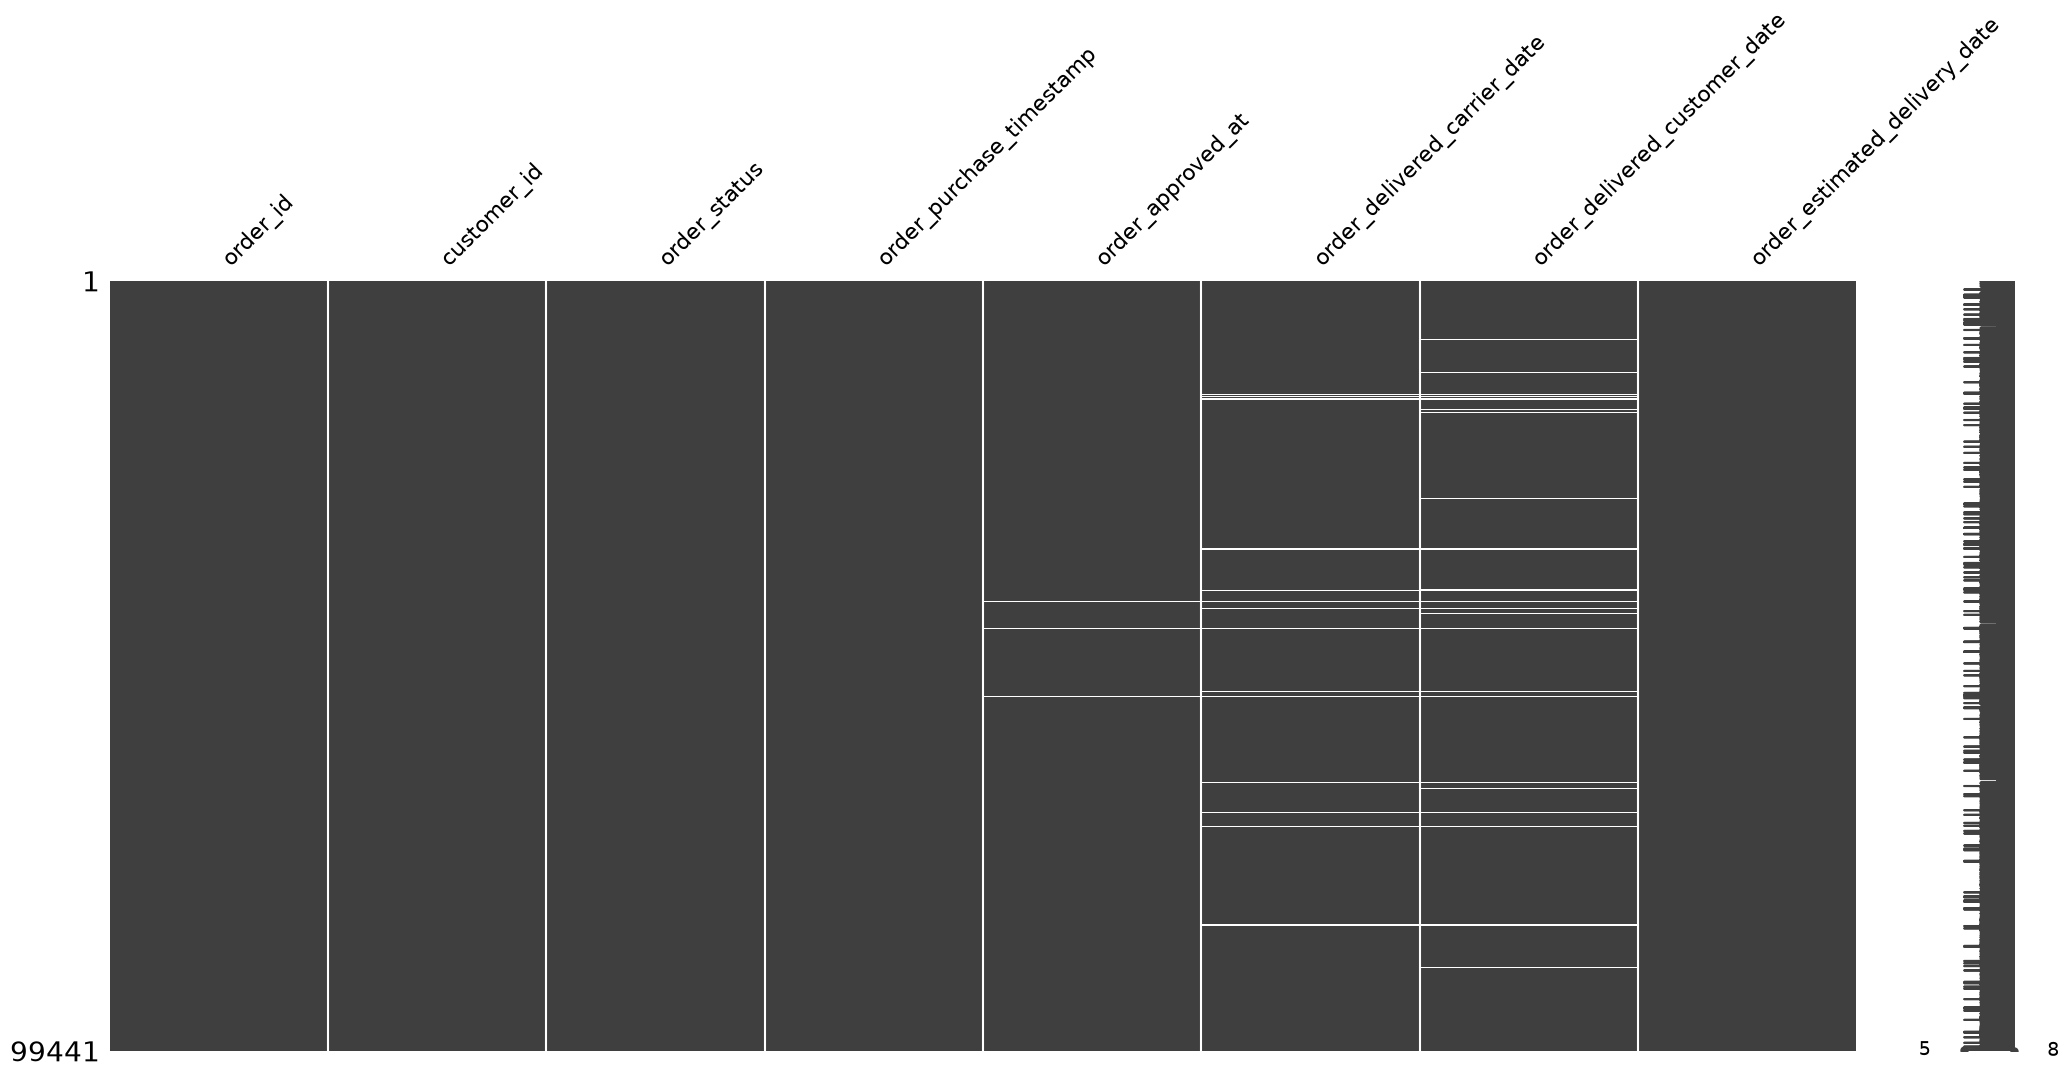

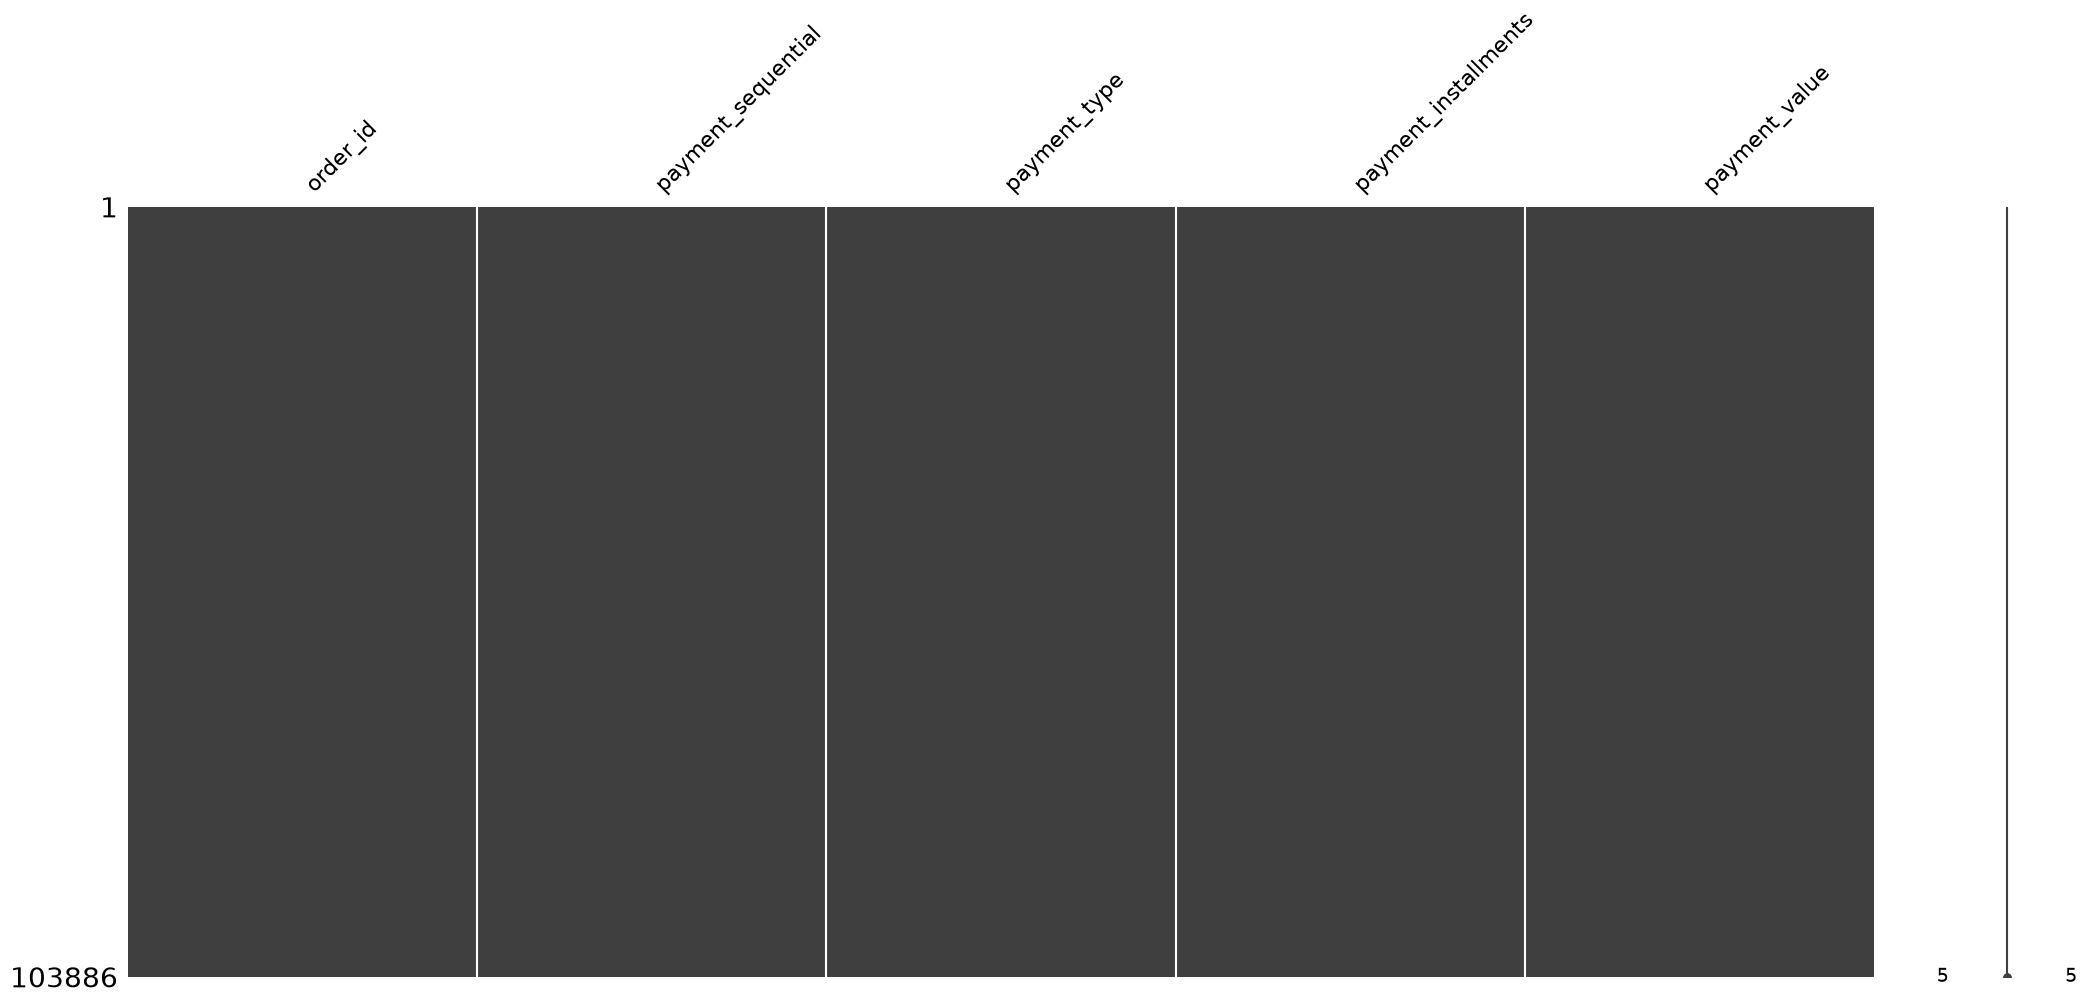

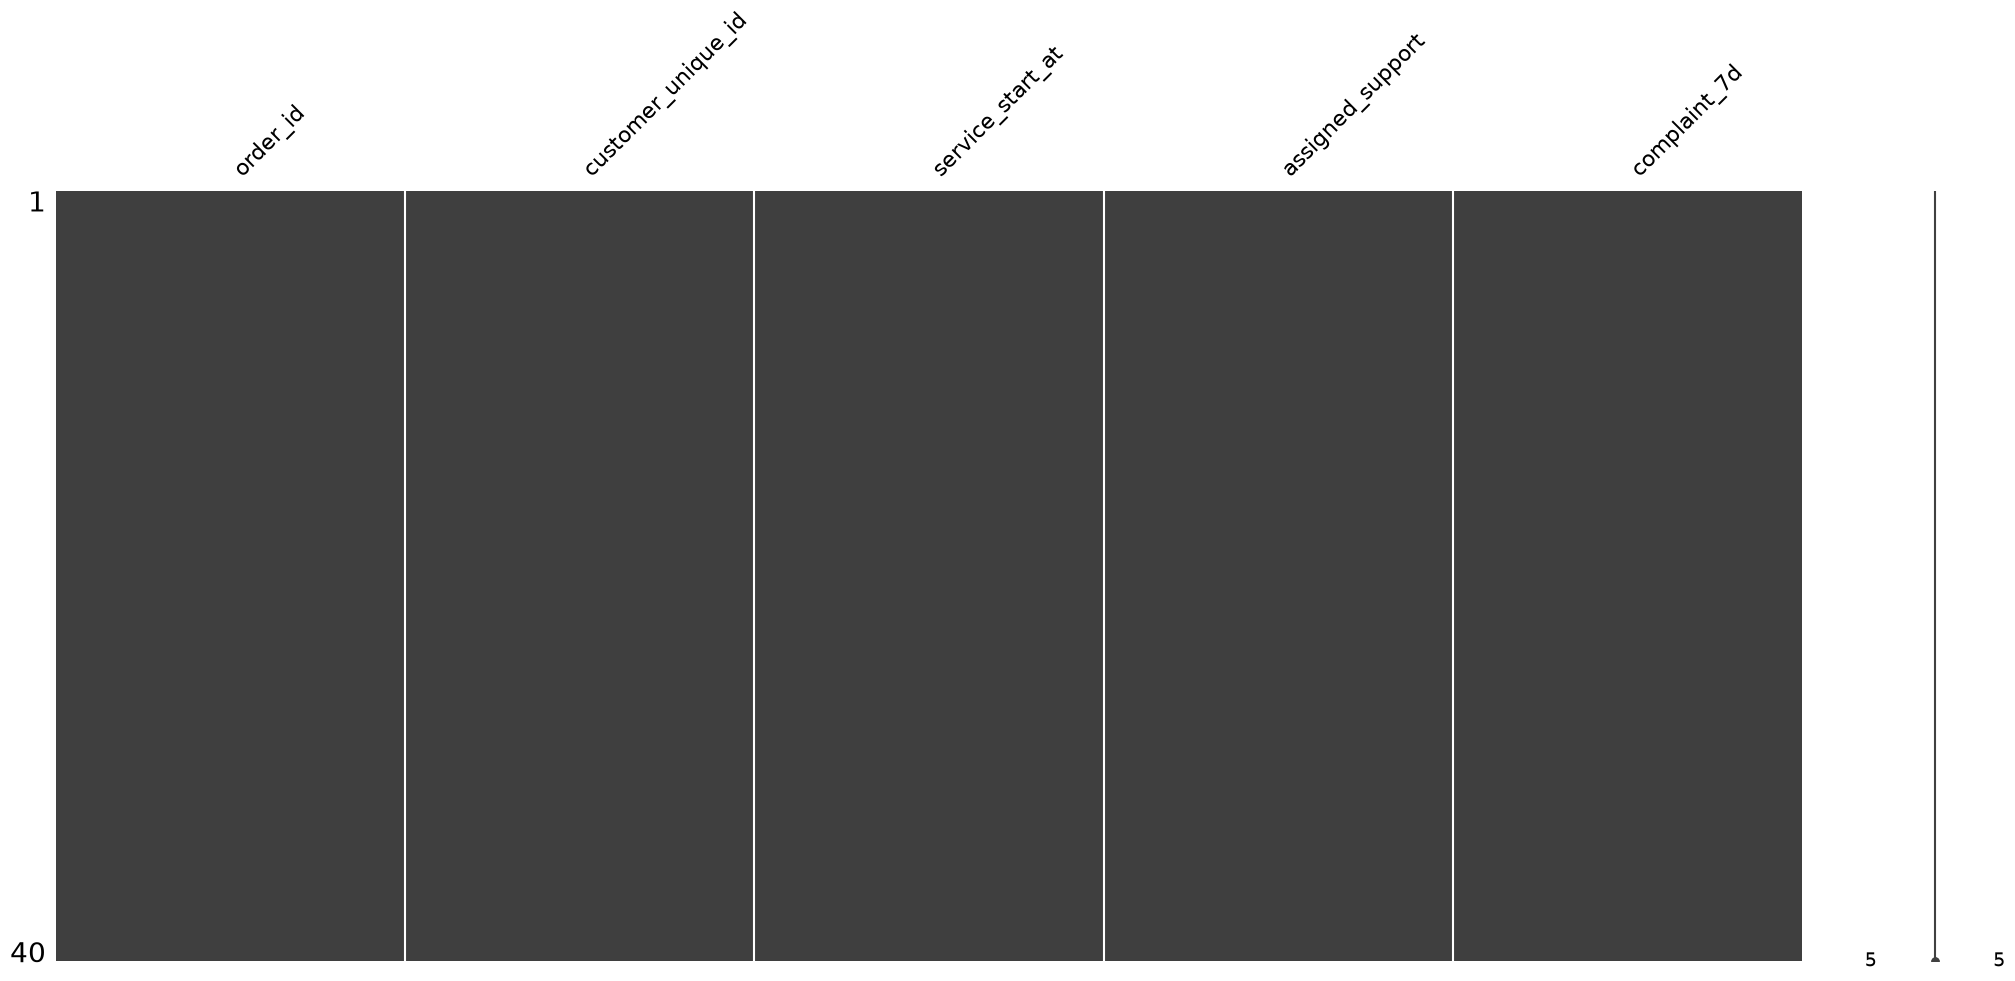

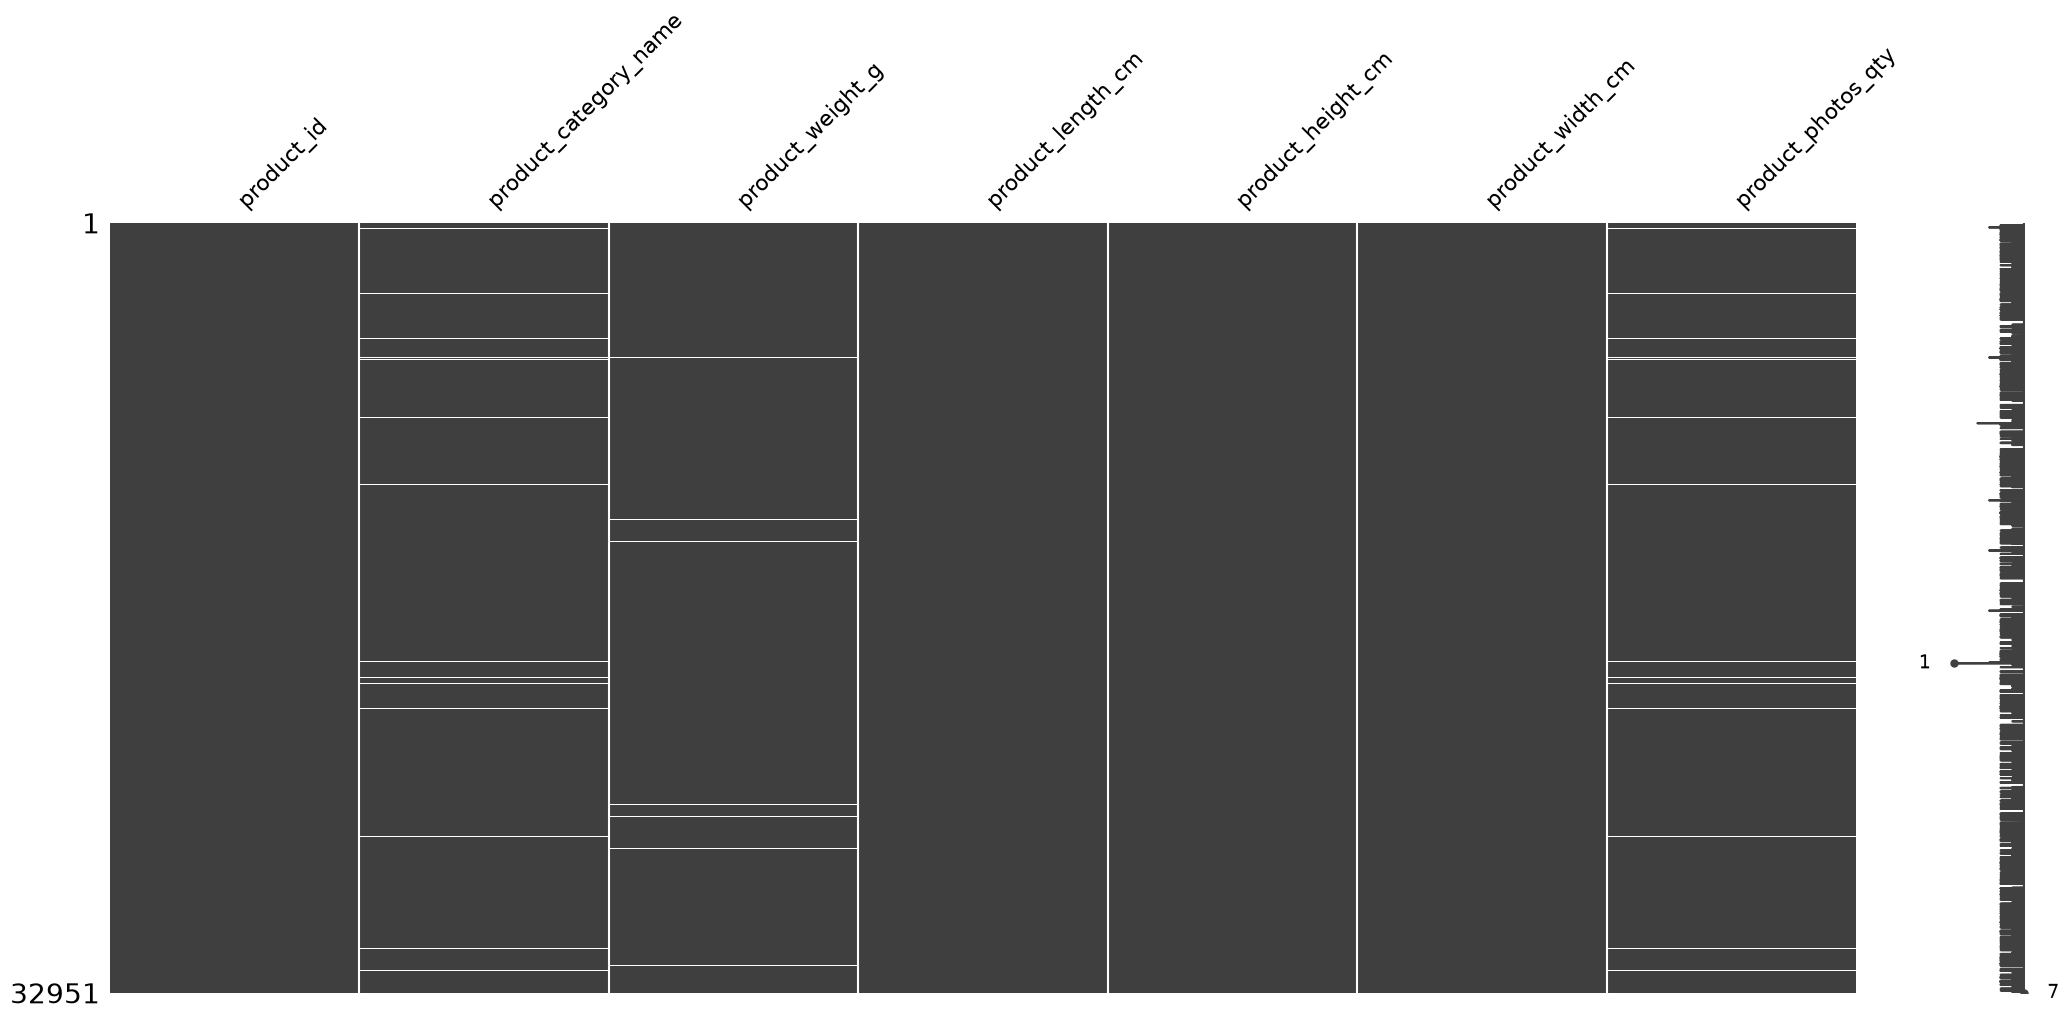

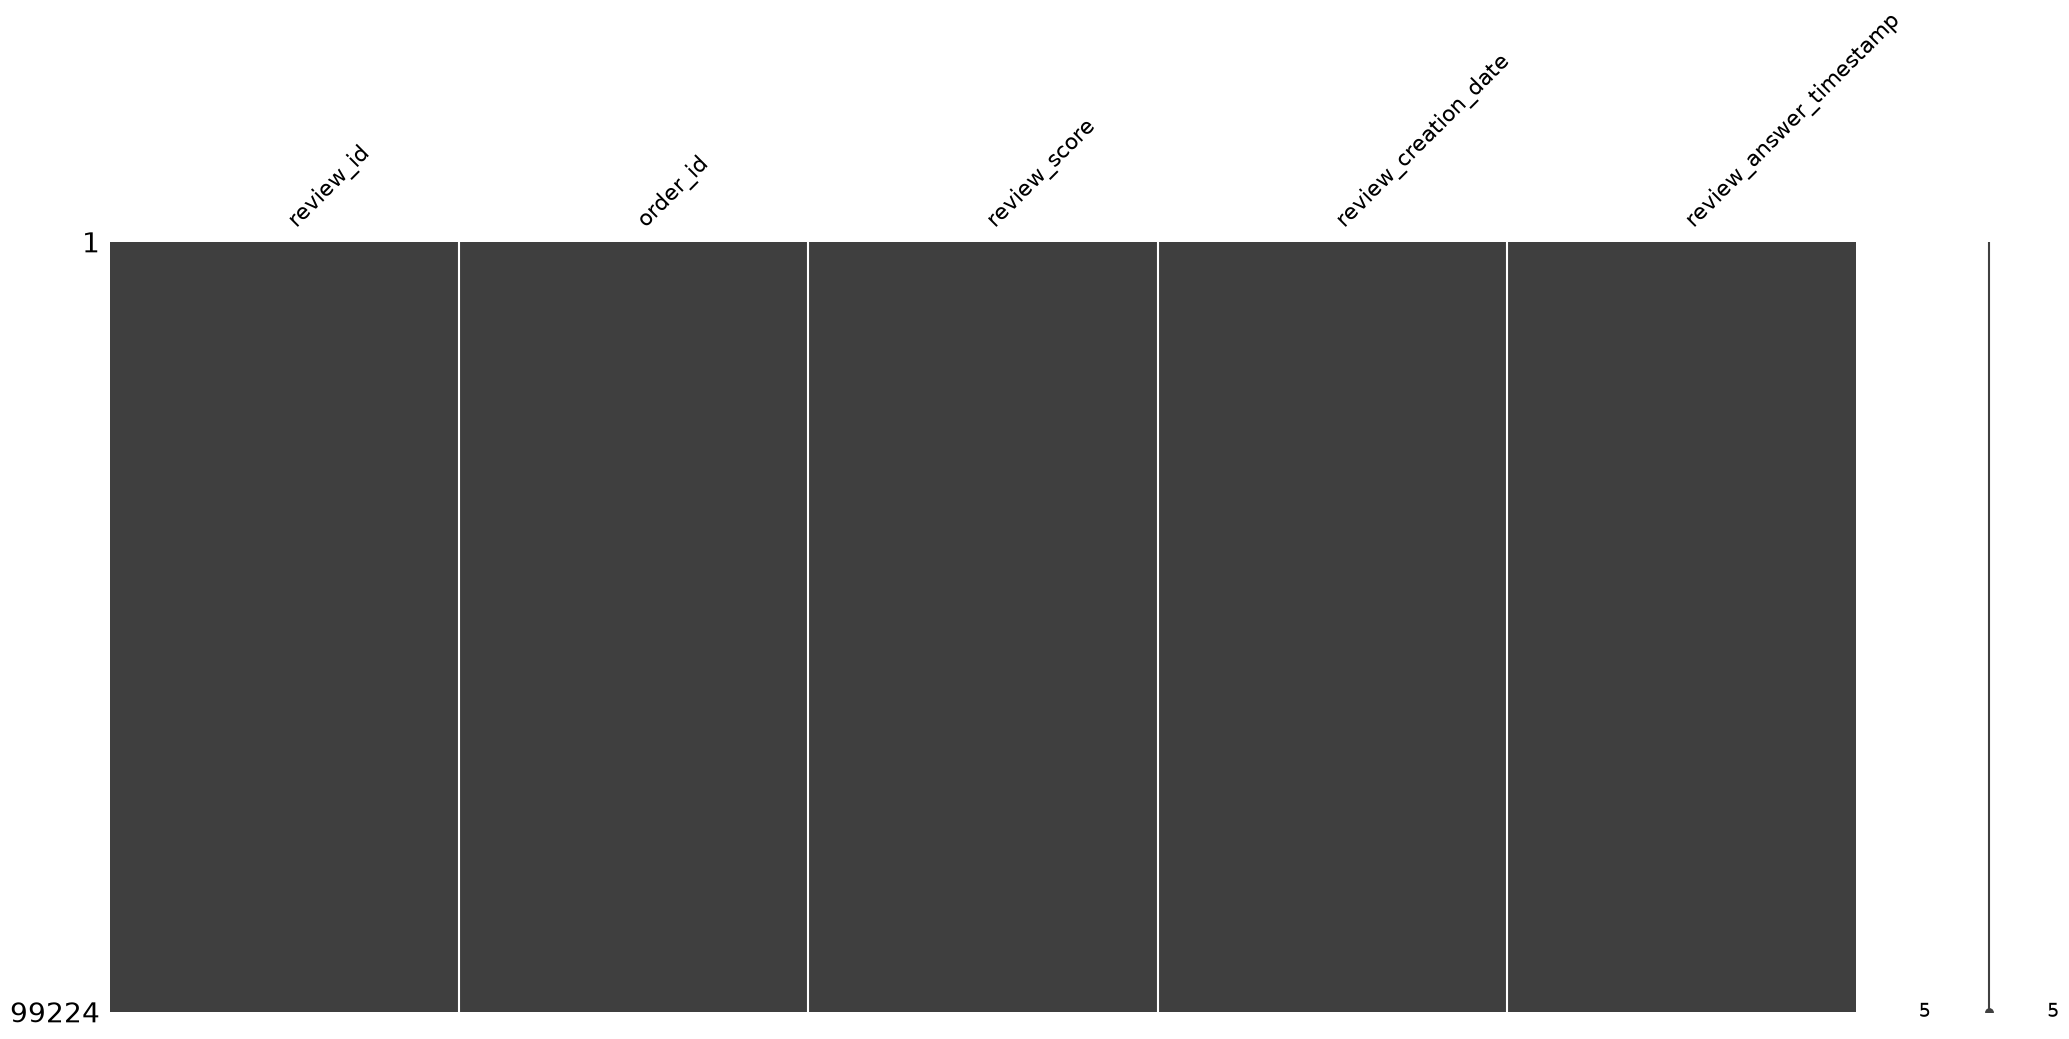

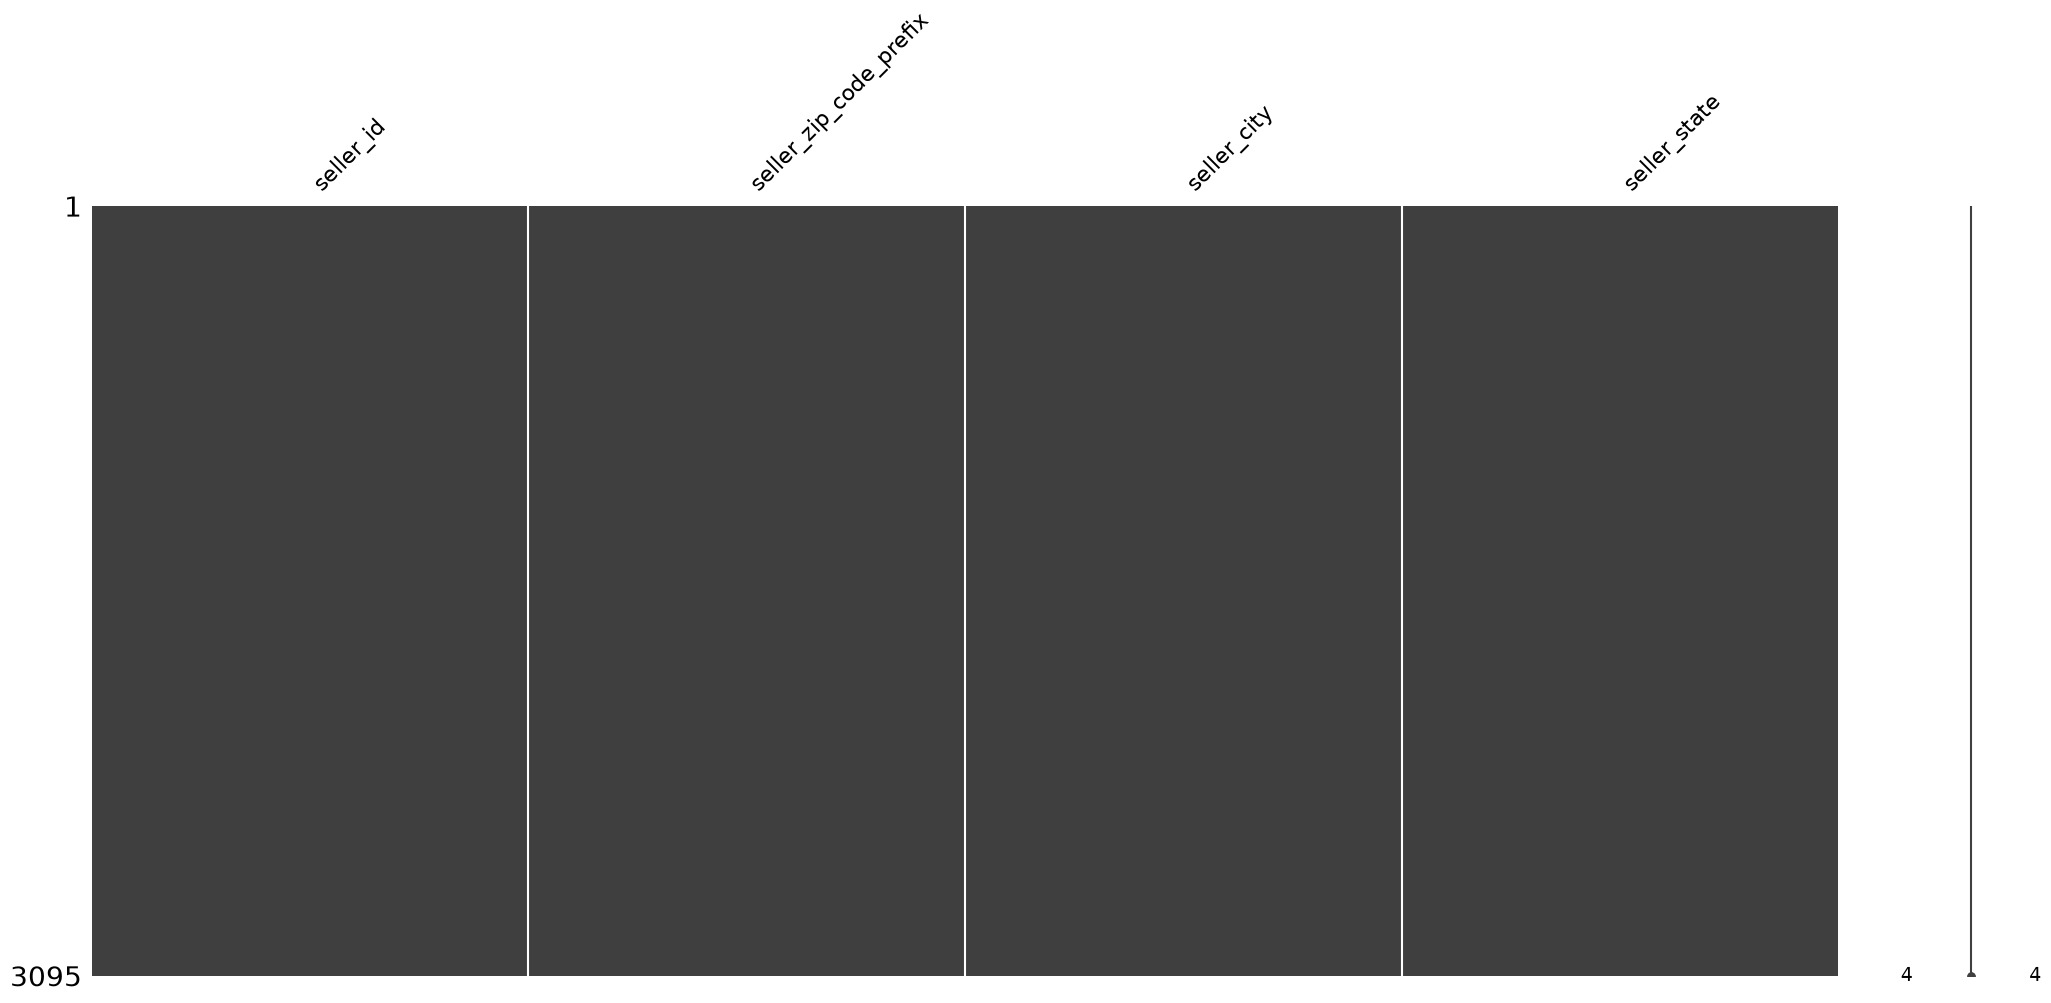

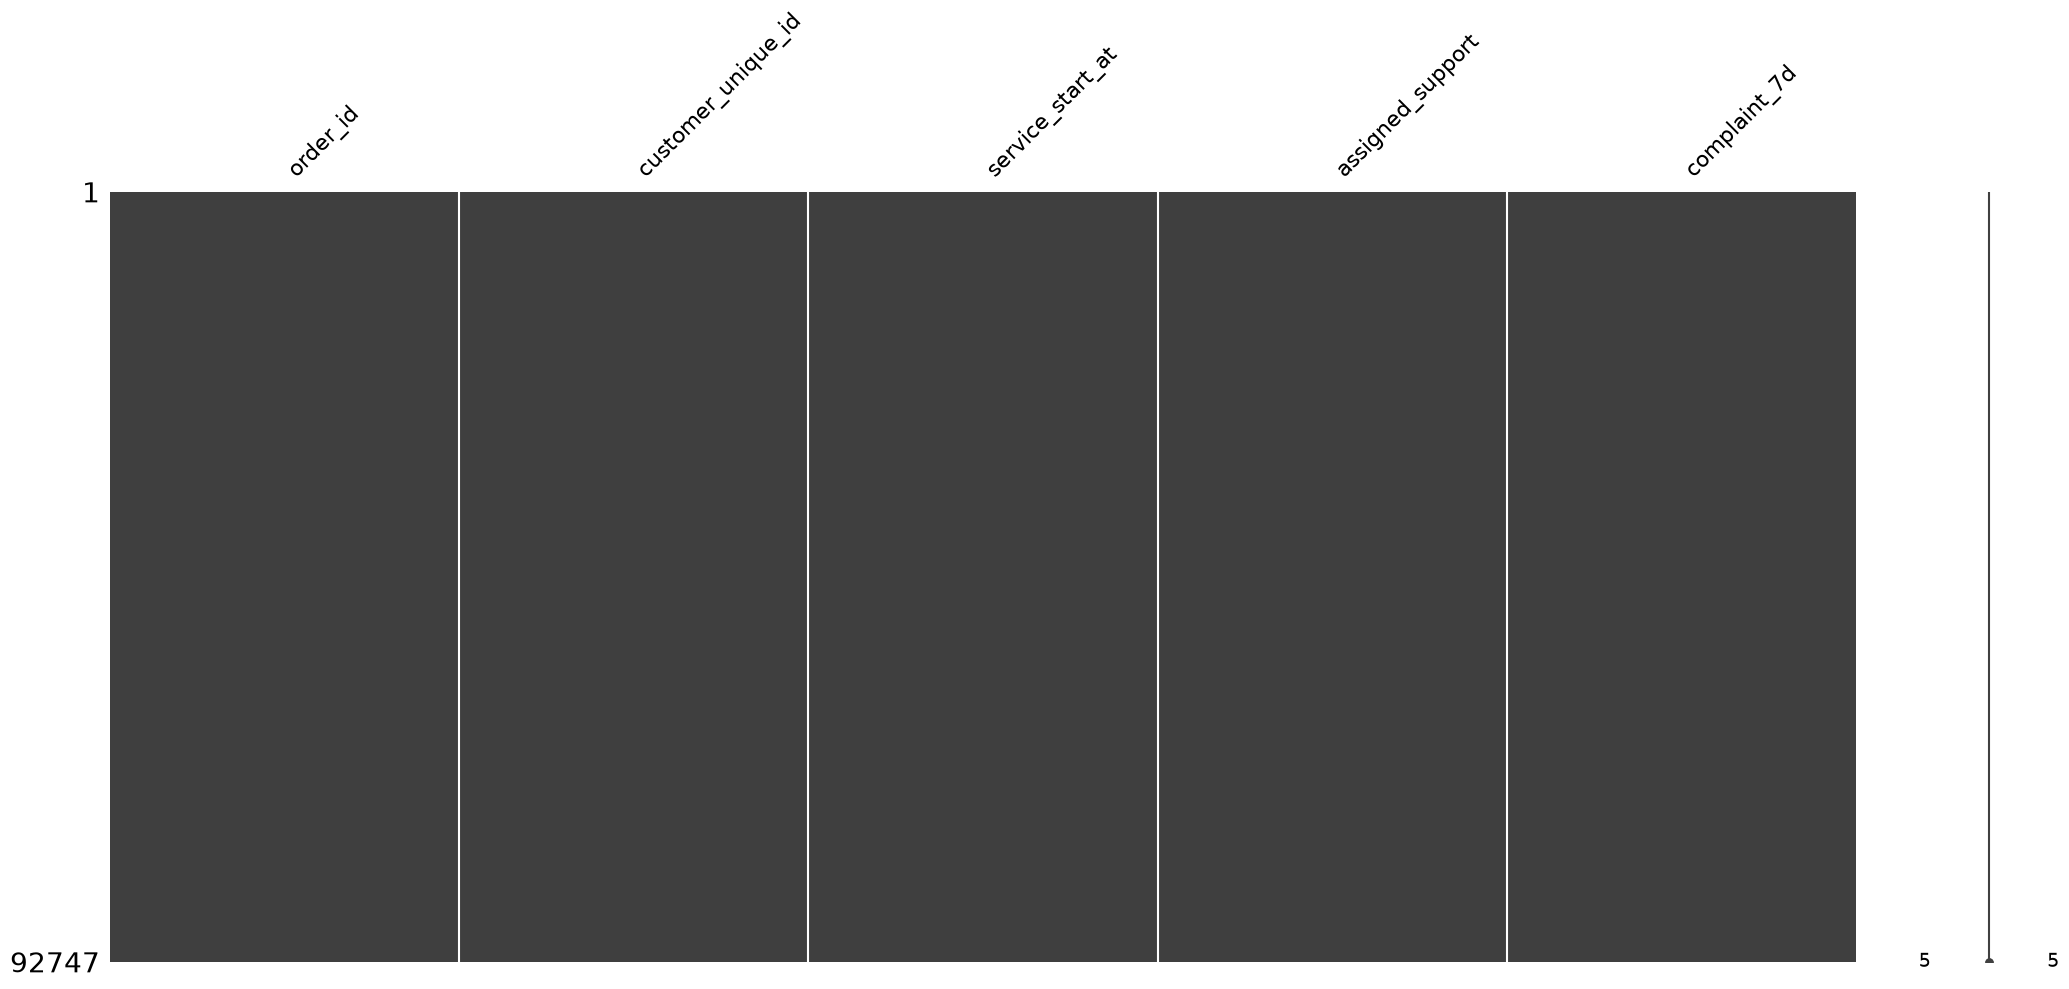

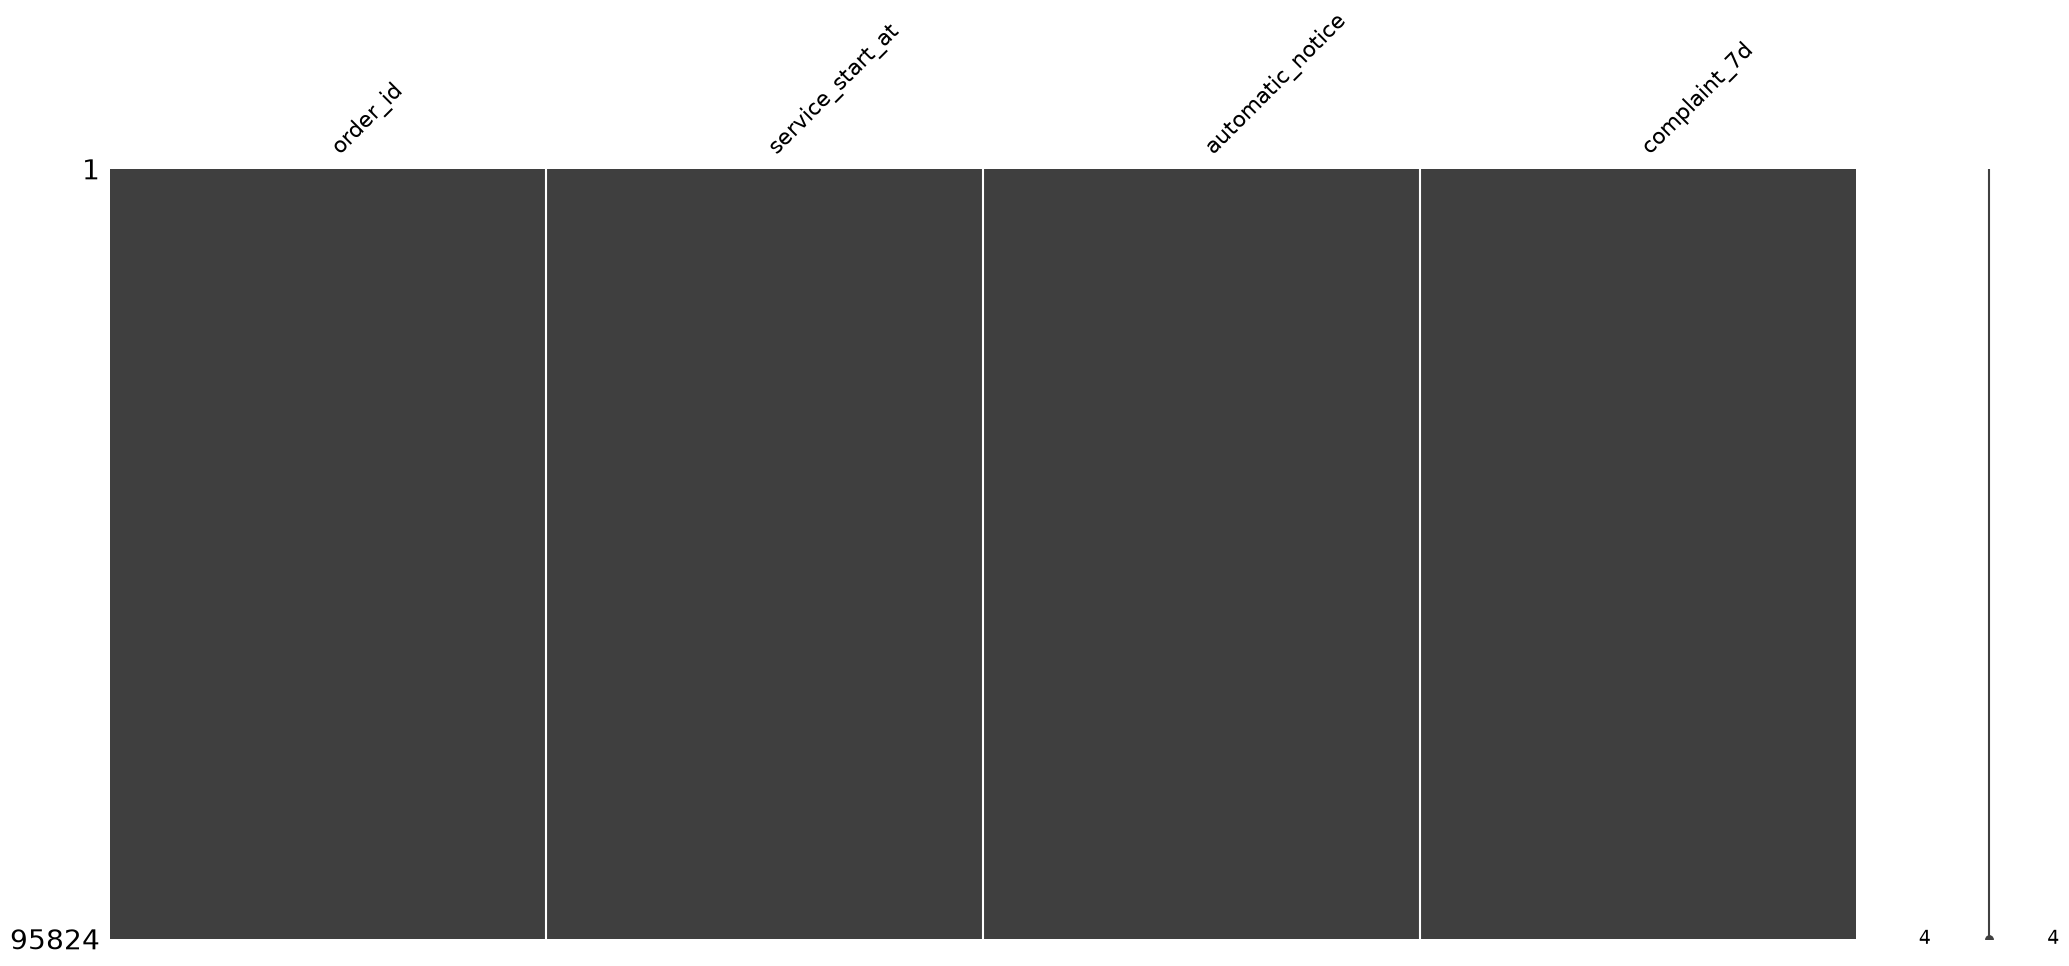

In [56]:
import missingno as msno

for i in dataframes:
    print(i)
    msno.matrix(dataframes[i])

In [61]:
dataframes["products"].nunique()

for i in dataframes:
    print(i)
    print(dataframes[i].nunique())
    print(dataframes[i].info())
    print("")

categories
product_category_name            73
product_category_name_english    71
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   product_category_name          73 non-null     str  
 1   product_category_name_english  71 non-null     str  
dtypes: str(2)
memory usage: 1.3 KB
None

customers
customer_id                 99441
customer_unique_id          96096
customer_zip_code_prefix    14994
customer_city                4119
customer_state                 27
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 

In [57]:
dataframes["products"].info()
for i in dataframes:
    print(i)
    msno.matrix(dataframes[i])

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   product_id             32951 non-null  str    
 1   product_category_name  32341 non-null  str    
 2   product_weight_g       32619 non-null  float64
 3   product_length_cm      32949 non-null  float64
 4   product_height_cm      32949 non-null  float64
 5   product_width_cm       32949 non-null  float64
 6   product_photos_qty     32341 non-null  float64
dtypes: float64(5), str(2)
memory usage: 1.8 MB


In [80]:
class bcolors:
    HEADER = '\033[95m'
    OKBLUE = '\033[94m'
    OKCYAN = '\033[96m'
    OKGREEN = '\033[92m'
    WARNING = '\033[93m'
    FAIL = '\033[91m'
    ENDC = '\033[0m'
    BOLD = '\033[1m'
    UNDERLINE = '\033[4m'



for i in dataframes:
    schluessel = [
        col for col in dataframes[i].columns
        if dataframes[i][col].notna().all()
        and dataframes[i][col].is_unique
    ]


    if schluessel == []:
        print(bcolors.WARNING + f"Schlüssel für {i} ist die Spalte: {schluessel}")
    else:
        print(bcolors.OKBLUE + f"Schlüssel für {i} ist die Spalte: {schluessel}")

Schlüssel für categories ist die Spalte: ['product_category_name']
Schlüssel für customers ist die Spalte: ['customer_id']
Schlüssel für geolocation ist die Spalte: []
Schlüssel für items ist die Spalte: []
Schlüssel für orders ist die Spalte: ['order_id', 'customer_id']
Schlüssel für payments ist die Spalte: []
Schlüssel für pilot_support ist die Spalte: ['order_id', 'customer_unique_id', 'service_start_at']
Schlüssel für products ist die Spalte: ['product_id']
Schlüssel für reviews ist die Spalte: []
Schlüssel für sellers ist die Spalte: ['seller_id']
Schlüssel für service_experiment ist die Spalte: ['order_id', 'customer_unique_id']
Schlüssel für service_observation ist die Spalte: ['order_id']


In [81]:
dataframes["payments"]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
...,...,...,...,...,...
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54


In [91]:
dataframes["payments"][
    dataframes["payments"].duplicated(keep=False)
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
